# Name-that-llm competition

### 1. Importing libraries

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2. First EDA

In [5]:
PATH = 'train.csv'
PATH_TEST = 'test.csv'
TARGET = 'model'

train = pd.read_csv(PATH)

d = train.copy()

test = pd.read_csv(PATH_TEST)

if d is None:
    print('data is NONE -')

if TARGET not in d.columns:
    print('your data has no target column -')

print("--- head ---")
display(d.head())
print("--- describe ---")
display(d.describe())
print("--- info ---")
display(d.info())
print('--- cols ---')
d.columns

--- head ---


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


--- describe ---


,id,prompt_id,text,model
count,2699,2699,2699,2699
unique,2699,150,2699,18
top,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
freq,1,18,1,150


--- info ---
<class 'pandas.DataFrame'>
RangeIndex: 2699 entries, 0 to 2698
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         2699 non-null   str  
 1   prompt_id  2699 non-null   str  
 2   text       2699 non-null   str  
 3   model      2699 non-null   str  
dtypes: str(4)
memory usage: 2.1 MB


None

--- cols ---


Index(['id', 'prompt_id', 'text', 'model'], dtype='str')

In [6]:
display(d['model'].value_counts())
d['model'].nunique()

model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
gpt-6-astra               150
glm-5.3                   150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64

18

In [7]:
d["char_count"] = d["text"].str.len()
d["word_count"] = d['text'].str.split().str.len()

print('average length of response -> ', d['char_count'].mean().__floor__())
print('average word count -> ', d['word_count'].mean().__floor__())

print('median length of response -> ', d['char_count'].median().__floor__())
print('median word count -> ', d['word_count'].median().__floor__(), '\n')

print("length description:")
print(d["char_count"].describe(), '\n')

print("\n word amount description:")
print(d["word_count"].describe(), '\n')

average length of response ->  755
average word count ->  114
median length of response ->  670
median word count ->  101 

length description:
count    2699.000000
mean      755.289366
std       377.371075
min       230.000000
25%       429.000000
50%       670.000000
75%      1027.000000
max      1900.000000
Name: char_count, dtype: float64 


 word amount description:
count    2699.000000
mean      114.659504
std        58.281372
min        36.000000
25%        64.000000
50%       101.000000
75%       157.000000
max       274.000000
Name: word_count, dtype: float64 



In [8]:
prompt_comparison = d[["prompt_id", "model", "word_count", "text"]].copy()

prompt_comparison = prompt_comparison.sort_values(
    ["prompt_id", "word_count"],
    ascending=[True, False]
)
# display(prompt_comparison.iloc[:18])
display(prompt_comparison.iloc[36:54])




,prompt_id,model,word_count,text
122,p002,gemini-3.7-flash,243,As we cross the threshold into the dawn of rad...
1165,p002,glm-5.3-flash,242,Synthetic biology stands poised to become the ...
833,p002,gpt-5.5,168,Synthetic biology is turning the cell from a m...
1254,p002,claude-opus-4-8,155,Imagine a future where we author life the way ...
282,p002,claude-sonnet-5,122,Imagine genomes written not by evolution's bli...
1057,p002,claude-opus-4-6,120,Synthetic biology stands at the threshold of a...
2534,p002,gemini-3.1-pro-preview,116,"We stand at the precipice of a new genesis, wh..."
1985,p002,gpt-6-astra,112,Synthetic biology is turning the genome into a...
2505,p002,gemini-3.8-flash,109,"As humanity masters the biological compiler, t..."
1460,p002,qwen3.8-max,104,Synthetic biology turns evolution into a progr...


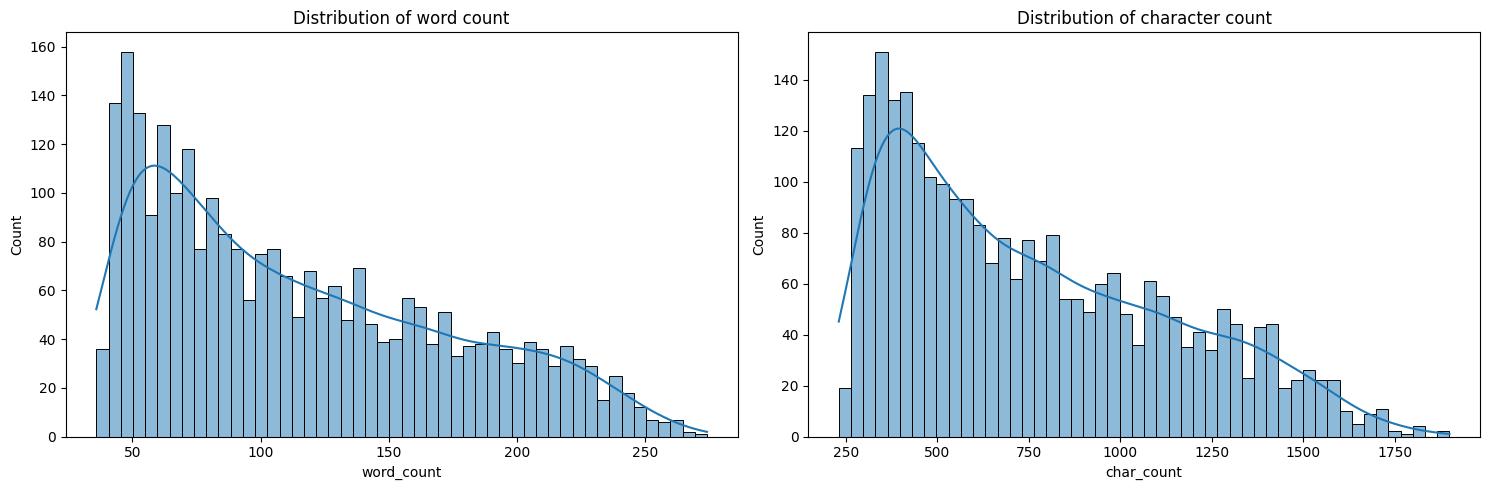

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=d, x="word_count", bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution of word count")

sns.histplot(data=d, x="char_count", bins=50, kde=True, ax=axes[1])
axes[1].set_title("Distribution of character count")

plt.tight_layout()
plt.show()

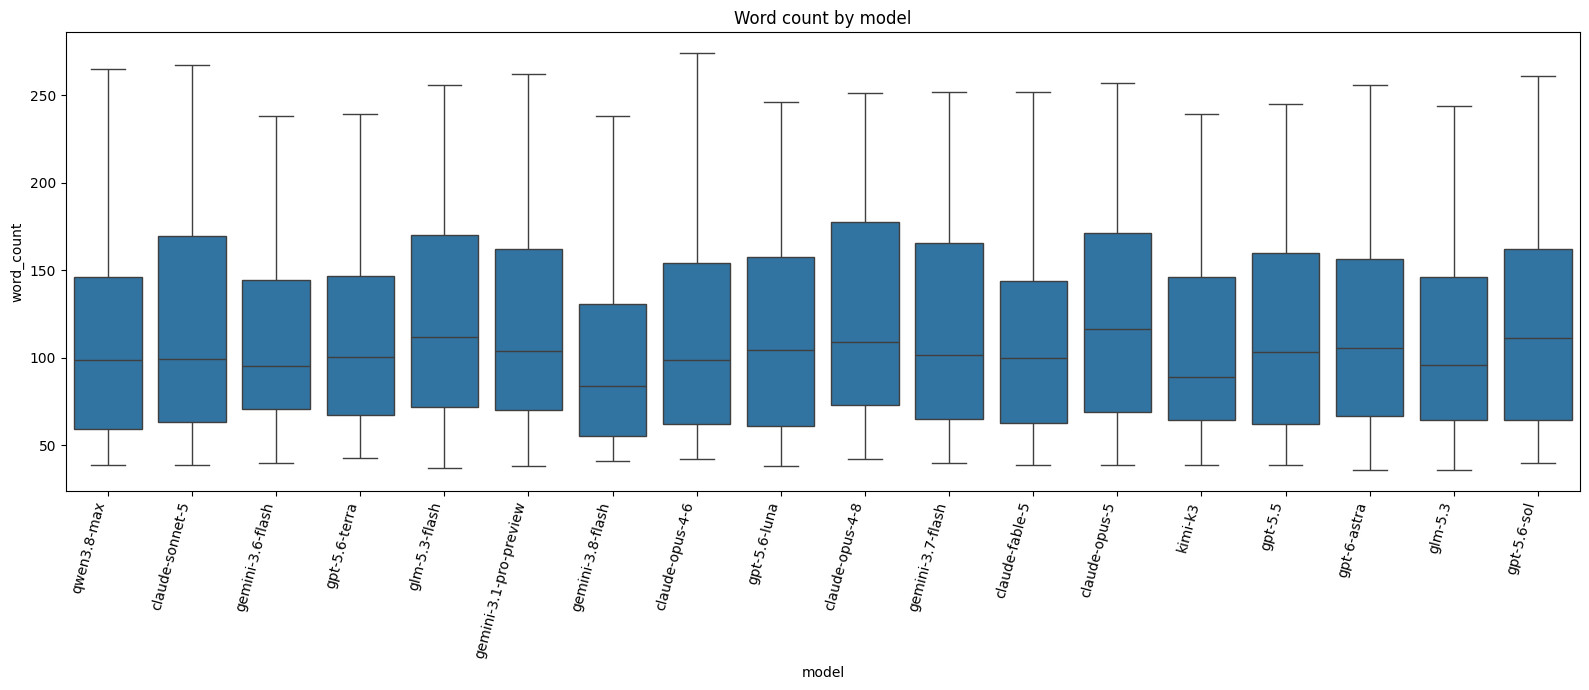

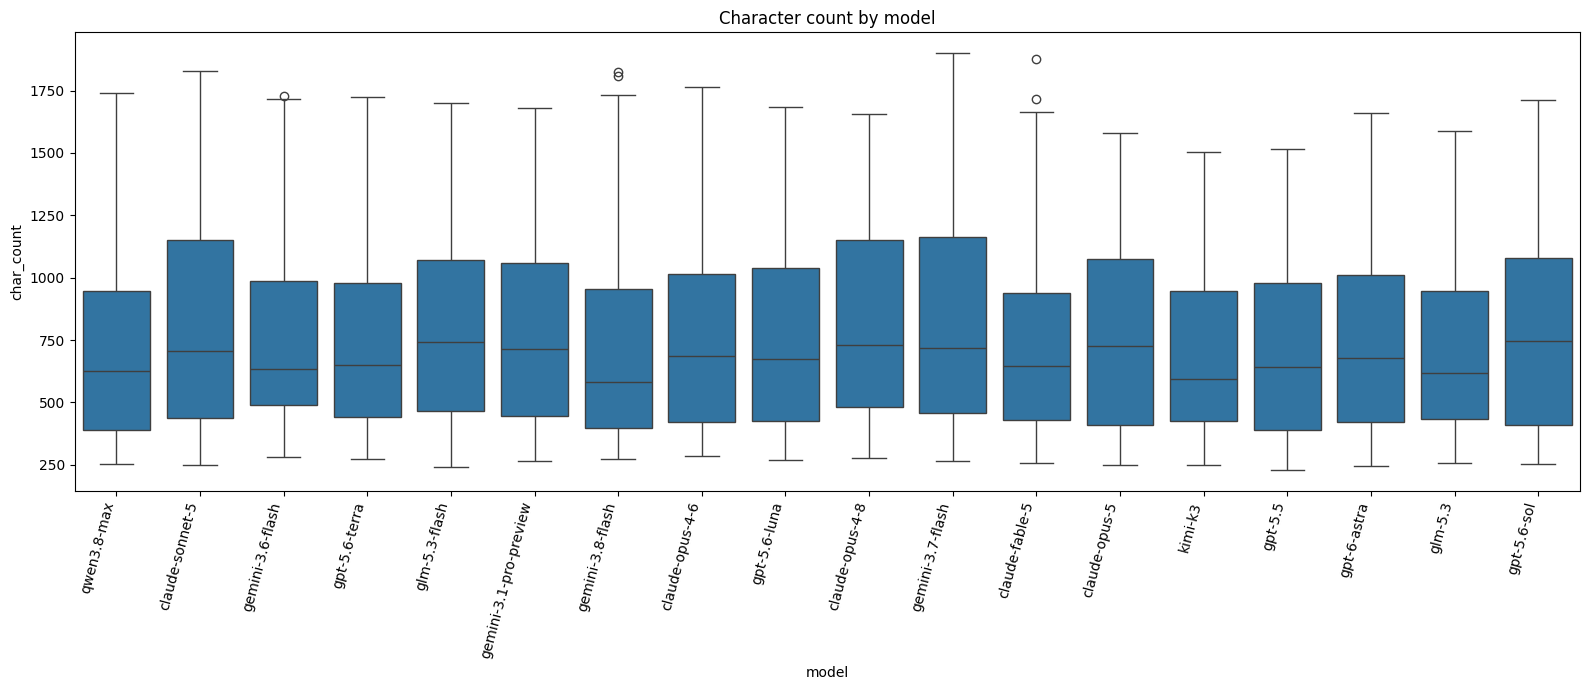

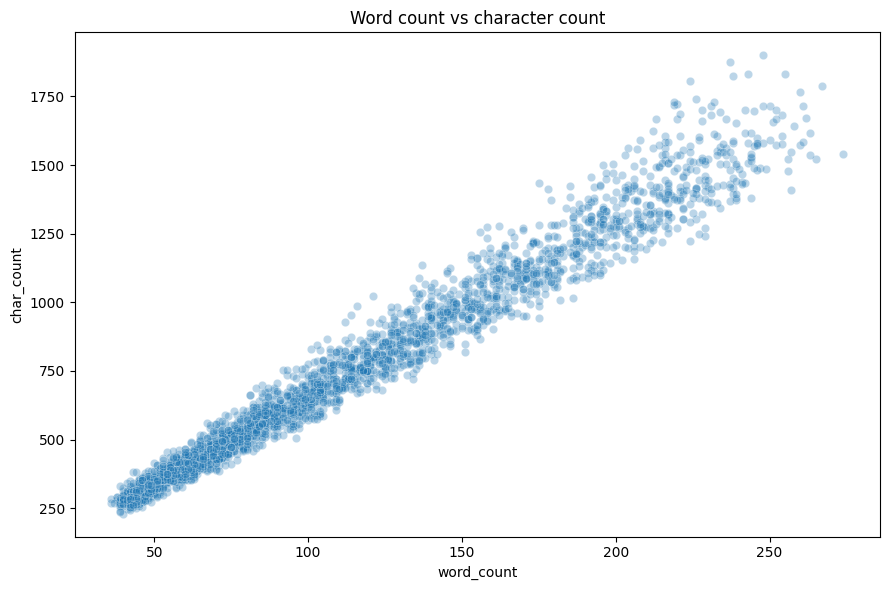

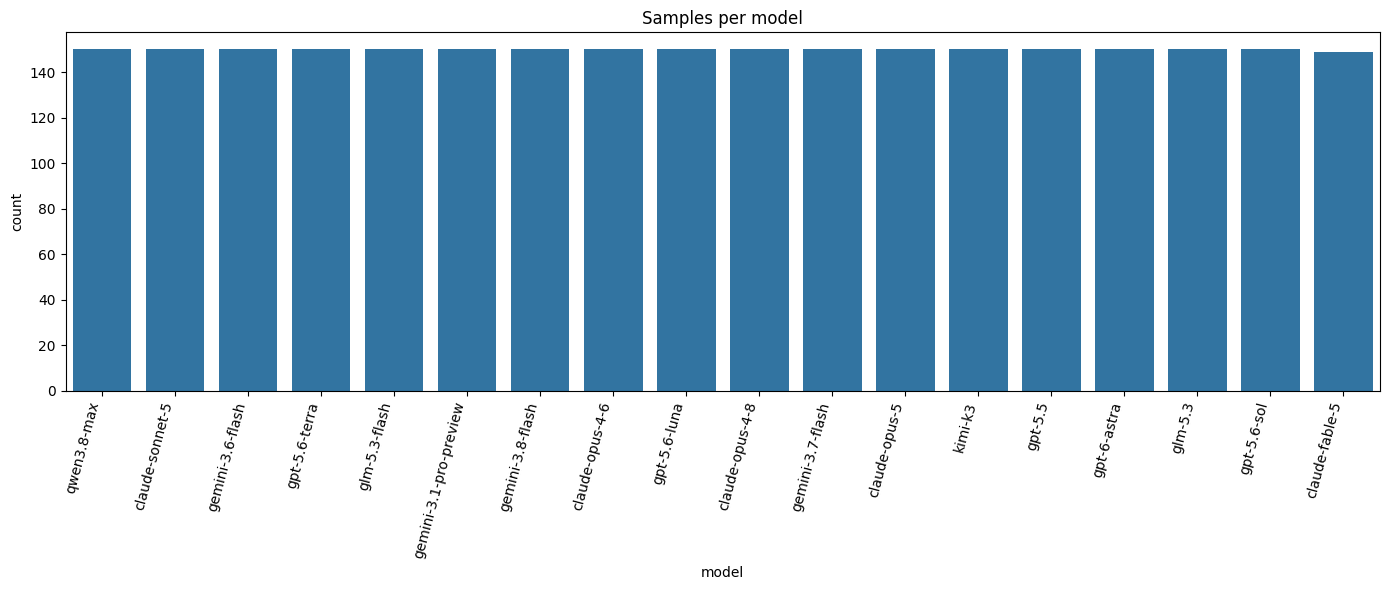

In [10]:
plt.figure(figsize=(16, 7))
sns.boxplot(data=d, x="model", y="word_count")
plt.xticks(rotation=75, ha="right")
plt.title("Word count by model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 7))
sns.boxplot(data=d, x="model", y="char_count")
plt.xticks(rotation=75, ha="right")
plt.title("Character count by model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=d, x="word_count", y="char_count", alpha=0.3)
plt.title("Word count vs character count")
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 6))
sns.countplot(data=d, x="model", order=d["model"].value_counts().index)
plt.xticks(rotation=75, ha="right")
plt.title("Samples per model")
plt.tight_layout()
plt.show()

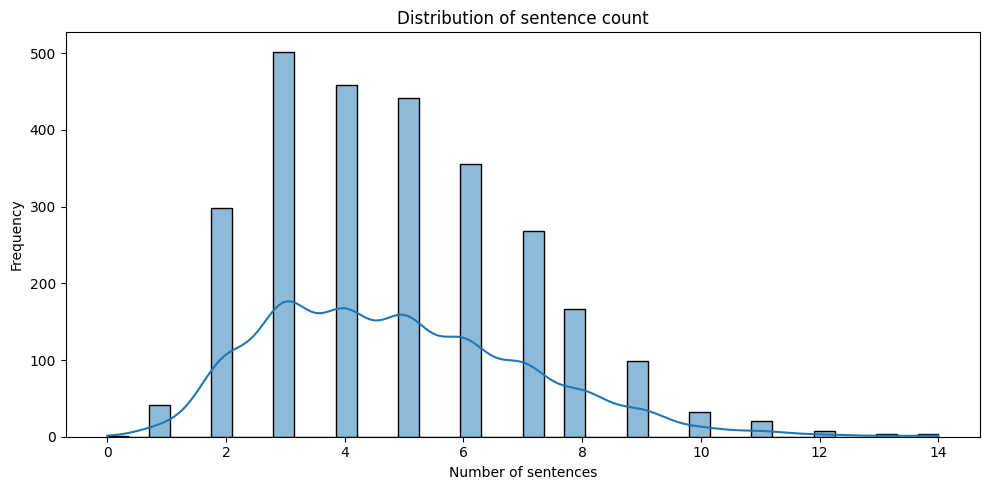

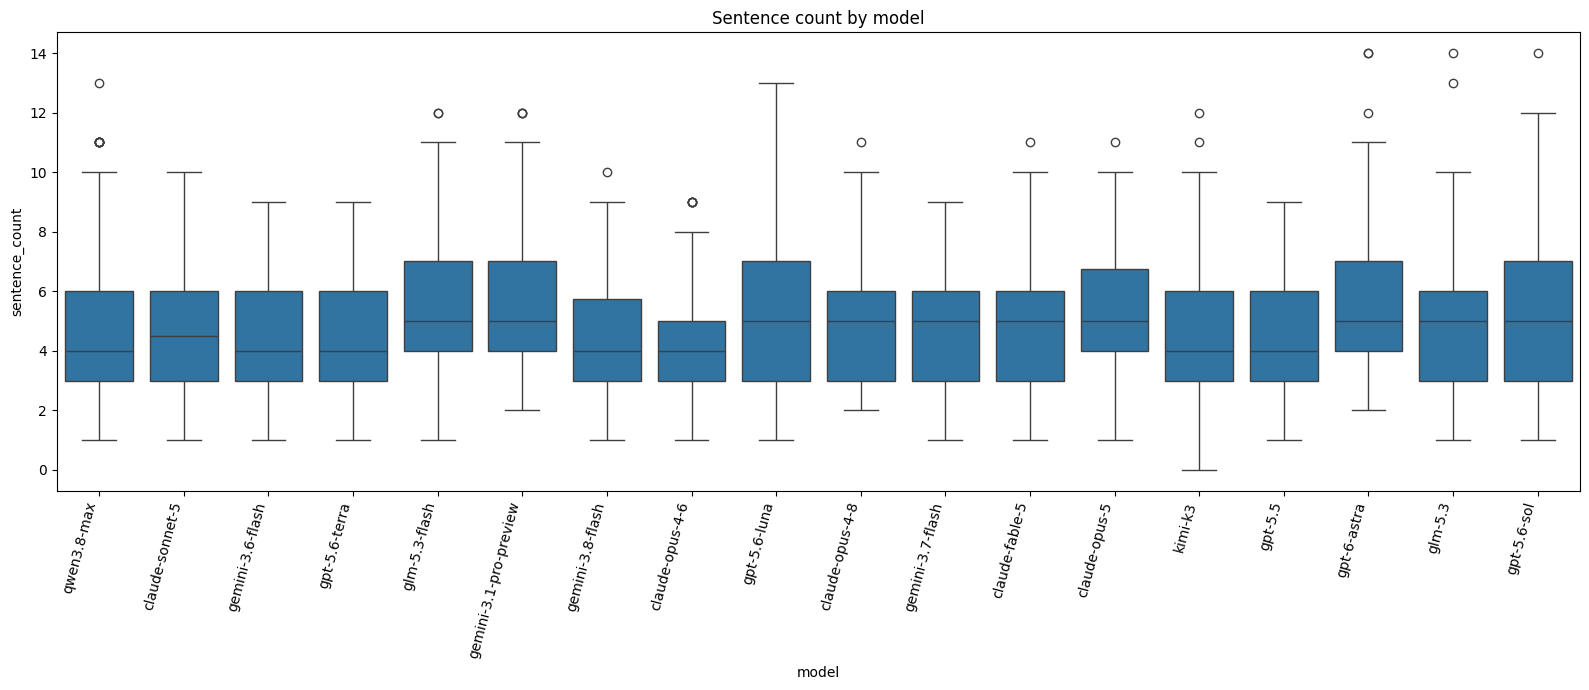

In [11]:
d["sentence_count"] = d["text"].str.count(r'[.!?]+')

plt.figure(figsize=(10, 5))
sns.histplot(data=d, x="sentence_count", bins=40, kde=True)
plt.title("Distribution of sentence count")
plt.xlabel("Number of sentences")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 7))
sns.boxplot(data=d, x="model", y="sentence_count")
plt.xticks(rotation=75, ha="right")
plt.title("Sentence count by model")
plt.tight_layout()
plt.show()

In [12]:
outliers = d[d["sentence_count"].between(12, 14)].sort_values(
    ["model", "sentence_count"],
    ascending=[True, False]
)

display(outliers[["model", "sentence_count", "word_count", "text", 'prompt_id']])

display(
    outliers.groupby("model")
    .size()
    .sort_values(ascending=False)
    .to_frame("outlier_count")
)

,model,sentence_count,word_count,text,prompt_id
454,gemini-3.1-pro-preview,12,243,Nestled at the intersection of Eternity Boulev...,p141
2127,gemini-3.1-pro-preview,12,227,"In the primordial crucible of a toxic Earth, s...",p129
2295,gemini-3.1-pro-preview,12,233,Imagine two heavily armed rivals locked in a r...,p003
2105,glm-5.3,14,244,Imagine you just cleaned your bedroom—clothes ...,p033
2325,glm-5.3,13,244,Picture a cube and imagine choosing a single p...,p011
517,glm-5.3-flash,12,195,"High above the poisoned oceans, the sky itself...",p117
775,glm-5.3-flash,12,256,"Deep in the body's crowded neighborhoods, an o...",p122
1375,gpt-5.6-luna,13,196,"At first, the room obeys every rule: moonlight...",p015
1308,gpt-5.6-sol,14,191,"At rise, King Alaric enters the chapel laughin...",p035
1648,gpt-5.6-sol,12,214,"At first, the screens showed only a few bright...",p117


,outlier_count
model,
gemini-3.1-pro-preview,3
gpt-6-astra,3
glm-5.3-flash,2
glm-5.3,2
gpt-5.6-sol,2
gpt-5.6-luna,1
kimi-k3,1
qwen3.8-max,1


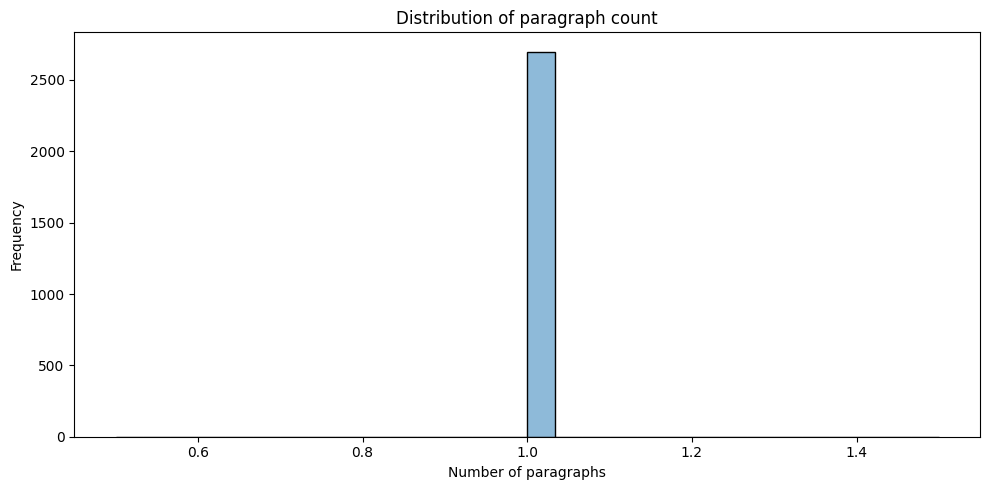

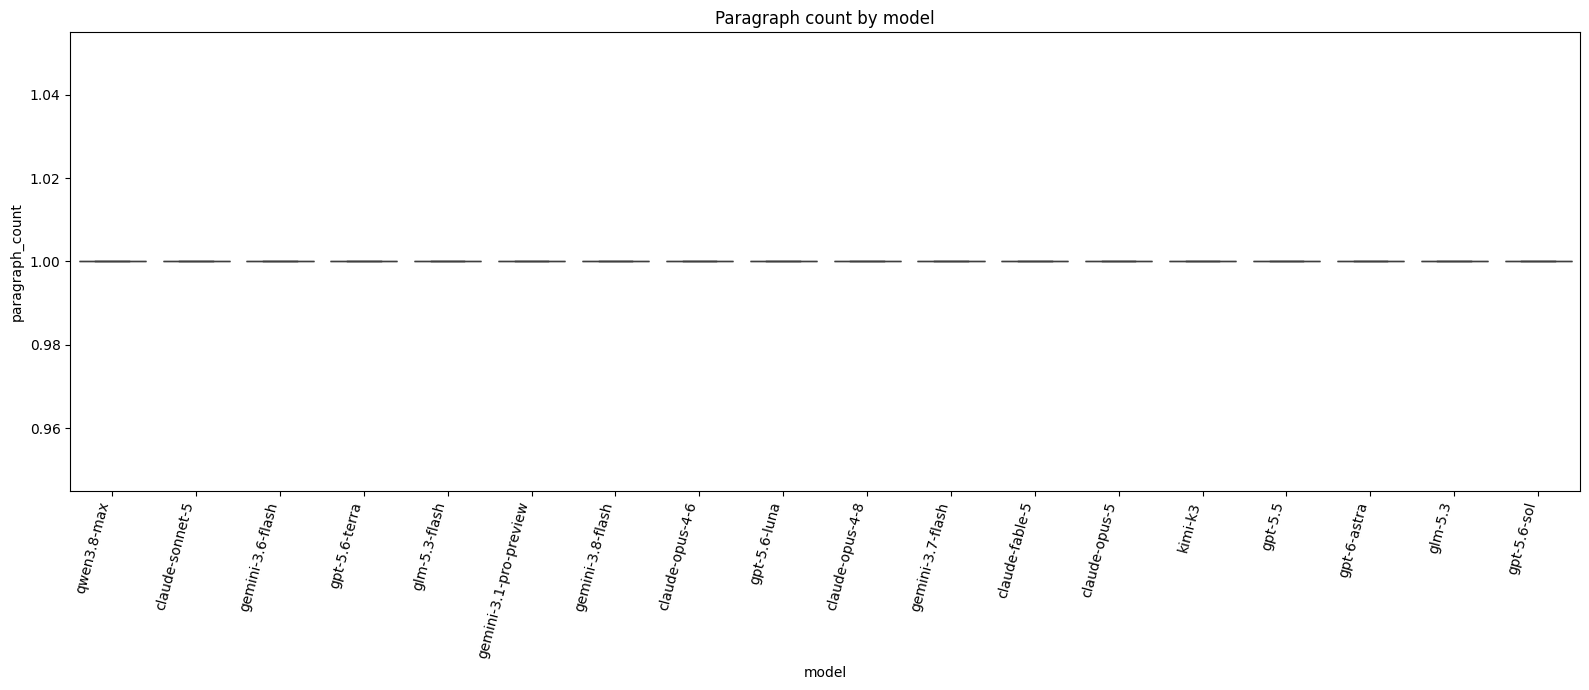

In [13]:
d["paragraph_count"] = d["text"].str.strip().str.split(r"\n\s*\n").str.len()

plt.figure(figsize=(10, 5))
sns.histplot(data=d, x="paragraph_count", bins=30, kde=True)
plt.title("Distribution of paragraph count")
plt.xlabel("Number of paragraphs")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 7))
sns.boxplot(data=d, x="model", y="paragraph_count")
plt.xticks(rotation=75, ha="right")
plt.title("Paragraph count by model")
plt.tight_layout()
plt.show()

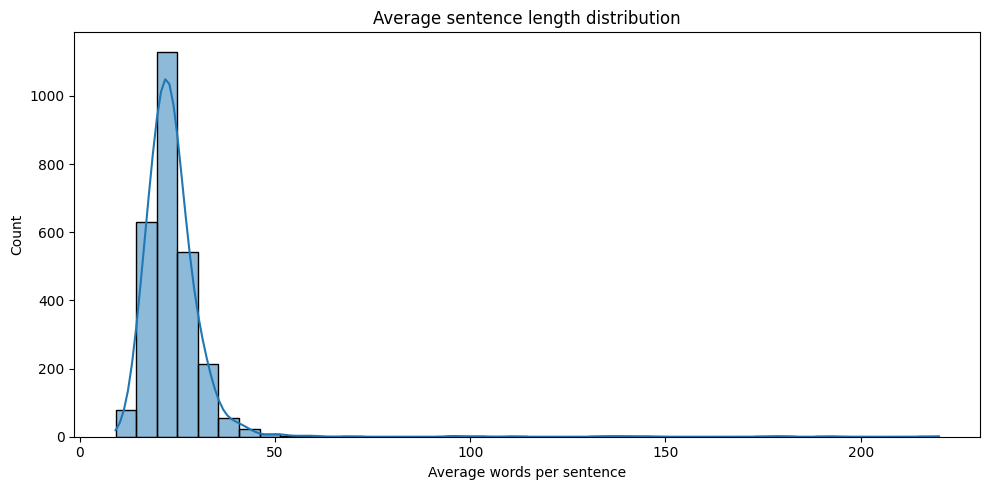

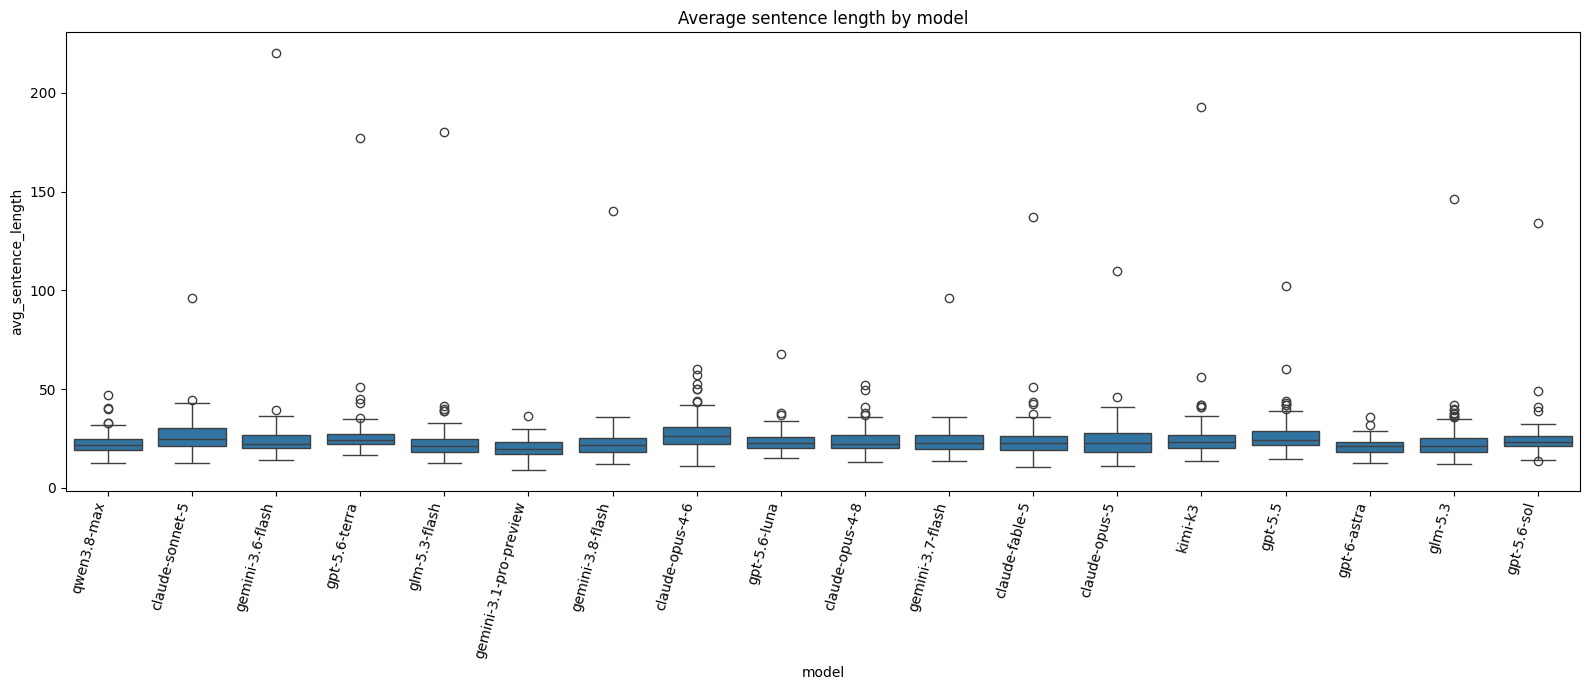

In [14]:
d["avg_sentence_length"] = d["word_count"] / d["sentence_count"].replace(0, 1)

plt.figure(figsize=(10, 5))
sns.histplot(data=d, x="avg_sentence_length", bins=40, kde=True)
plt.title("Average sentence length distribution")
plt.xlabel("Average words per sentence")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 7))
sns.boxplot(data=d, x="model", y="avg_sentence_length")
plt.xticks(rotation=75, ha="right")
plt.title("Average sentence length by model")
plt.tight_layout()
plt.show()

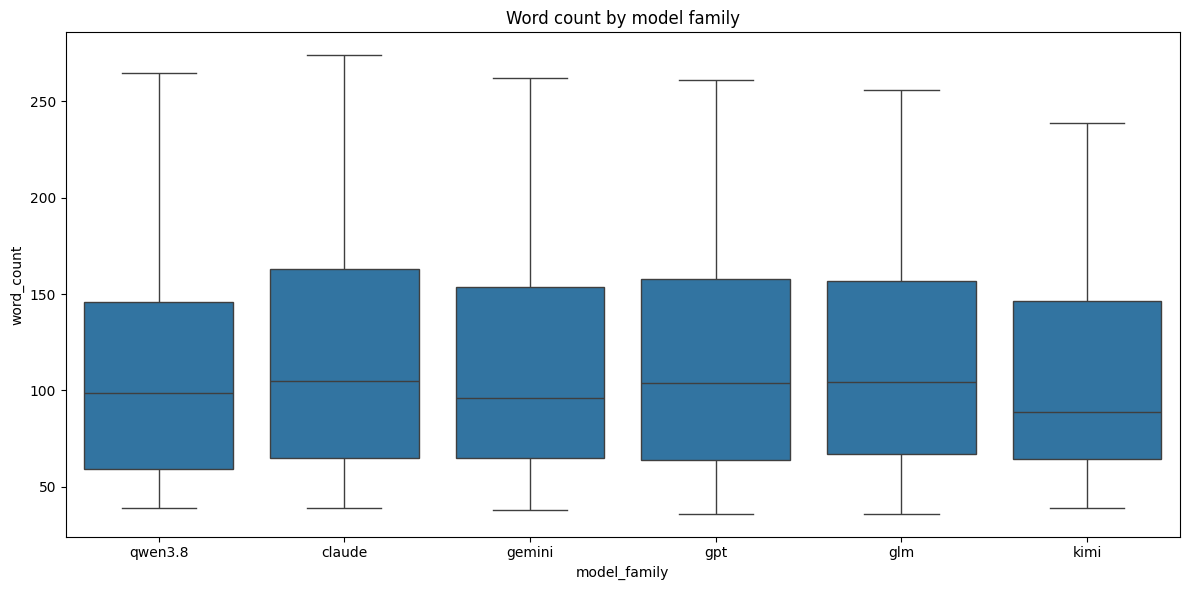

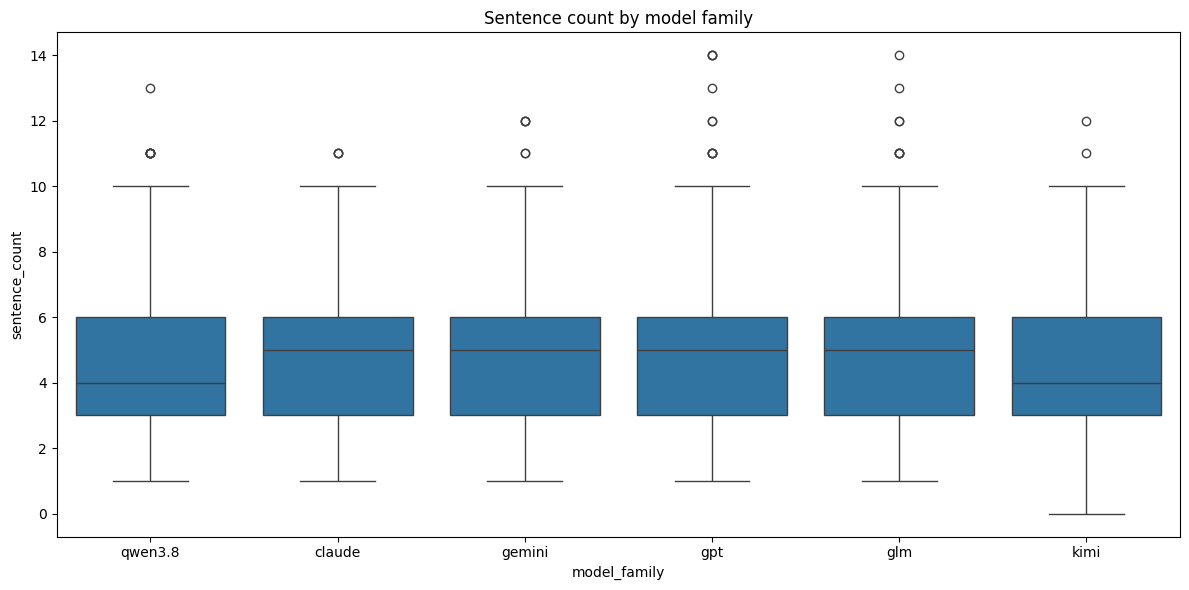

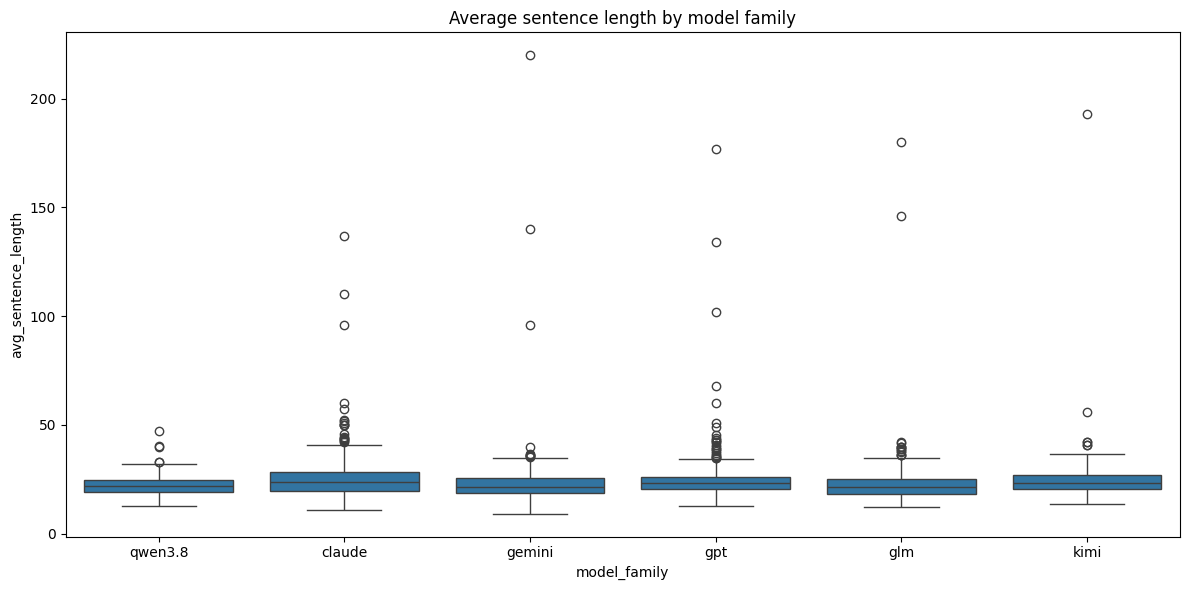

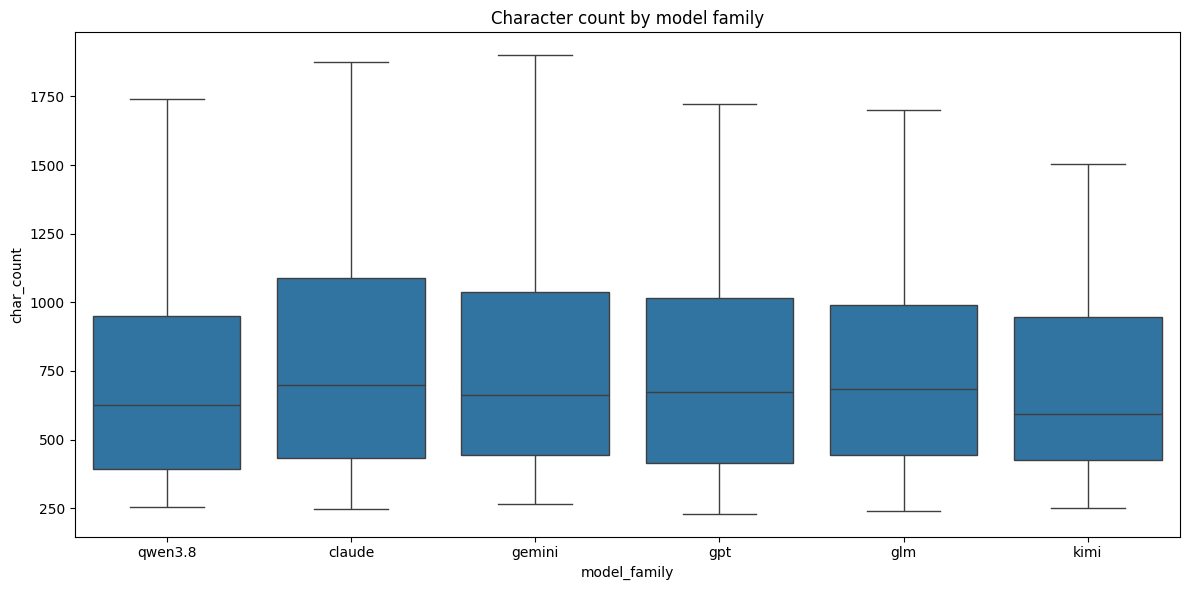

In [15]:
d['model_family'] = d['model'].str.split('-').str[0]

plt.figure(figsize=(12, 6))
sns.boxplot(data=d, x="model_family", y="word_count")
plt.title("Word count by model family")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=d, x="model_family", y="sentence_count")
plt.title("Sentence count by model family")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=d, x="model_family", y="avg_sentence_length")
plt.title("Average sentence length by model family")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=d, x="model_family", y="char_count")
plt.title("Character count by model family")
plt.tight_layout()
plt.show()

In [16]:
import re

d["words"] = d["text"].apply(
    lambda text: re.findall(r"\b\w+\b", text.lower())
)

d[["text", "words"]].head()

d['TTR'] = d['words'].apply(lambda words: len(set(words)) / len(words))
d['TTR'].head()

0    0.709845
1    0.925373
2    0.818182
3    0.810811
4    0.787879
Name: TTR, dtype: float64

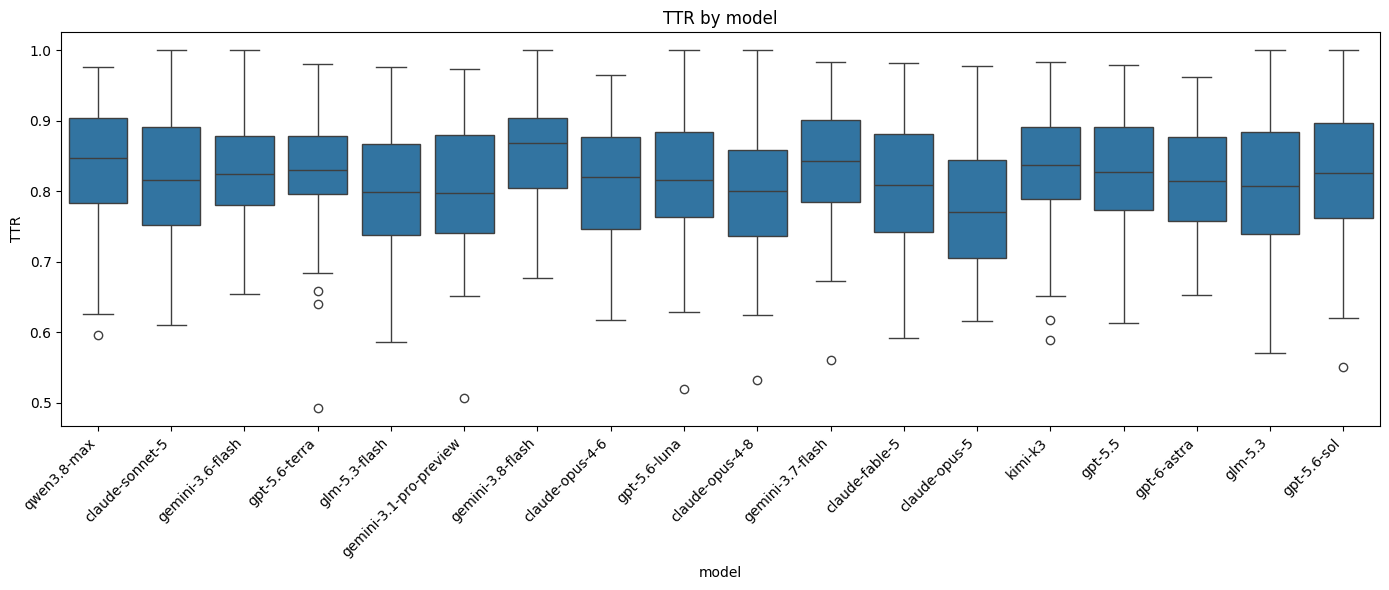

,mean,median,std,min,max
model,,,,,
claude-fable-5,0.809281,0.809524,0.089448,0.592275,0.981818
claude-opus-4-6,0.812547,0.819831,0.083064,0.617647,0.964286
claude-opus-4-8,0.799205,0.800943,0.085491,0.531746,1.000000
claude-opus-5,0.780172,0.769936,0.087837,0.615385,0.977778
claude-sonnet-5,0.817303,0.815301,0.085760,0.610000,1.000000
gemini-3.1-pro-preview,0.804112,0.797894,0.086269,0.506024,0.973684
gemini-3.6-flash,0.827349,0.825121,0.068813,0.653846,1.000000
gemini-3.7-flash,0.839313,0.843077,0.077168,0.560166,0.982759
gemini-3.8-flash,0.859368,0.868627,0.070028,0.677419,1.000000


In [17]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=d, x="model", y="TTR")
plt.xticks(rotation=45, ha="right")
plt.title("TTR by model")
plt.tight_layout()
plt.show()

d.groupby("model")["TTR"].agg(
    ["mean", "median", "std", "min", "max"]
)

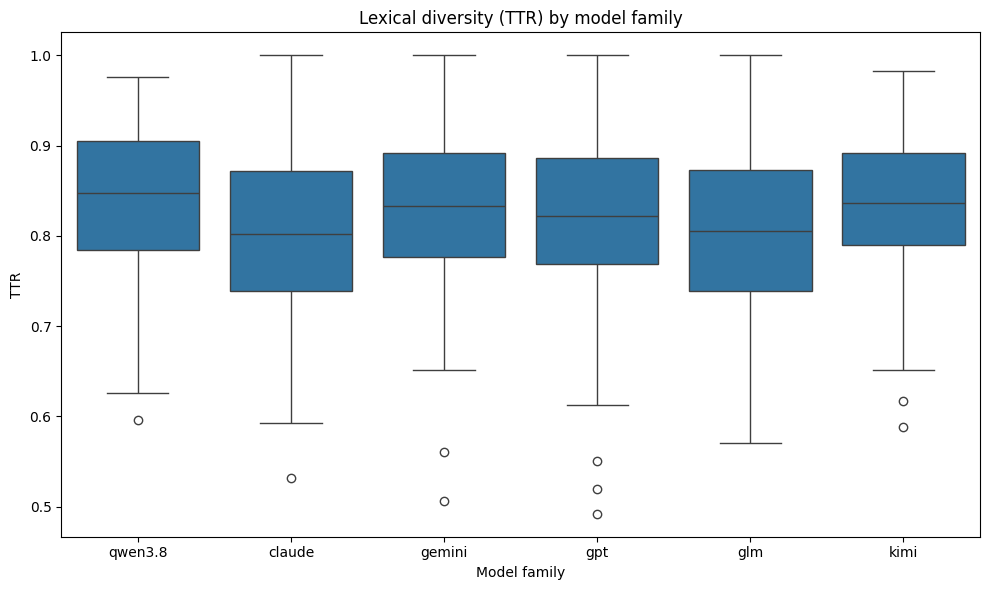

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=d, x="model_family", y="TTR")
plt.title("Lexical diversity (TTR) by model family")
plt.xlabel("Model family")
plt.ylabel("TTR")
plt.tight_layout()
plt.show()

In [19]:
d['rep_words'] = d['words'].apply(lambda words: 1 - (len(set(words)) / len(words)))

d['rep_words'].head()

0    0.290155
1    0.074627
2    0.181818
3    0.189189
4    0.212121
Name: rep_words, dtype: float64

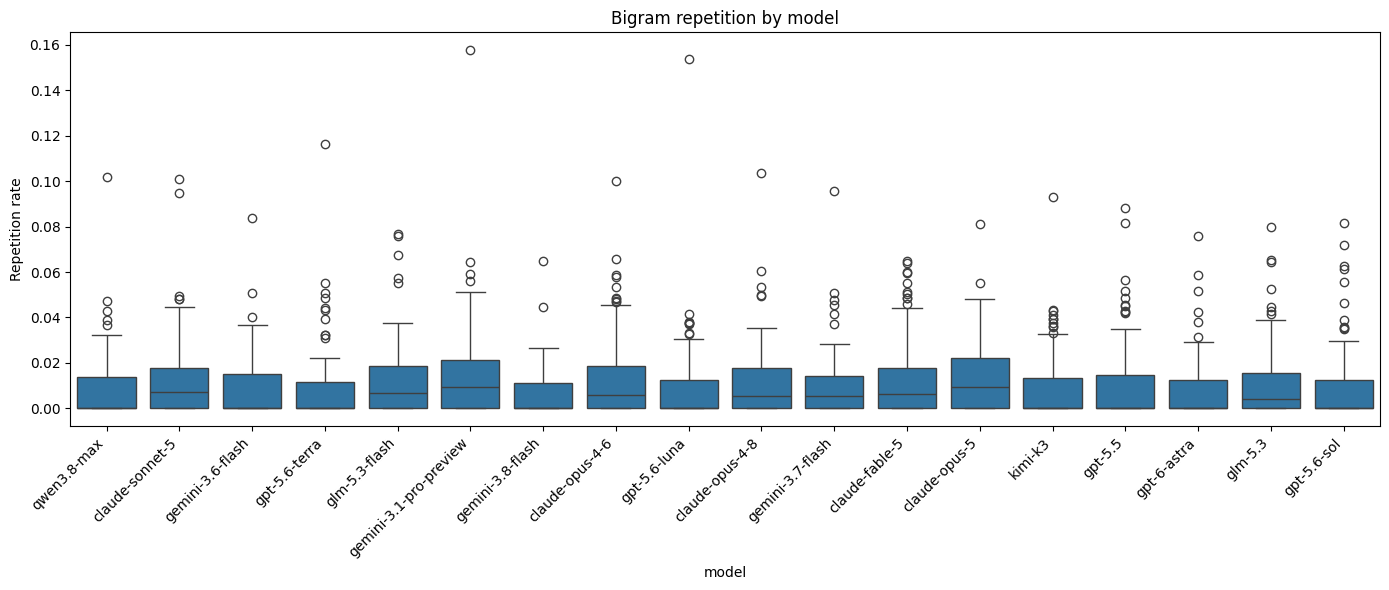

In [20]:
def bigram_repetition(words):
    bigrams = list(zip(words, words[1:]))

    if not bigrams:
        return 0

    return 1 - len(set(bigrams)) / len(bigrams)

d["bigram_repetition"] = d["words"].apply(bigram_repetition)

plt.figure(figsize=(14, 6))
sns.boxplot(data=d, x="model", y="bigram_repetition")
plt.xticks(rotation=45, ha="right")
plt.title("Bigram repetition by model")
plt.ylabel("Repetition rate")
plt.tight_layout()
plt.show()

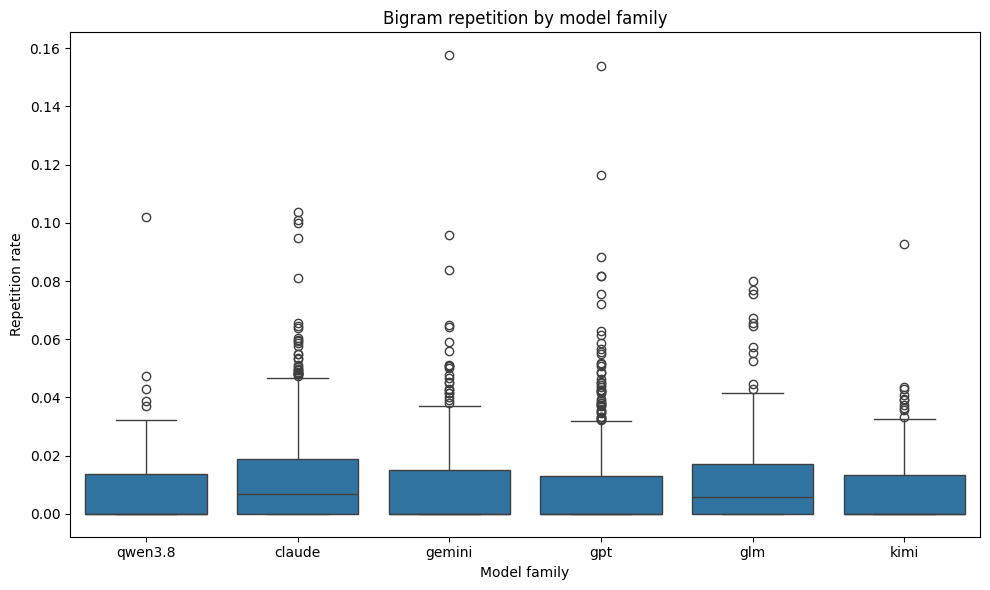

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=d, x="model_family", y="bigram_repetition")
plt.title("Bigram repetition by model family")
plt.xlabel("Model family")
plt.ylabel("Repetition rate")
plt.tight_layout()
plt.show()

In [196]:

def count_commas(text):
    k = 0
    for c in text:
        if c == ',':
            k += 1

    return k

def count_tires(text):
    k = 0
    for c in text:
        if c == '-':
            k += 1

    return k


d['comma_count'] = d['text'].apply(lambda x: count_commas(x))
d['tire_amount'] = d['text'].apply(lambda x: count_tires(x))
d['comma_div_sentence'] = d['comma_count'] / d['sentence_count']
d['no_sentences'] = (d['sentence_count'] == 0).astype(int)
d['comma_div_sentence'] = d['comma_div_sentence'].fillna(0)

from collections import Counter

d['hapax_ratio'] = d['words'].apply(
    lambda words: sum(1 for count in Counter(words).values() if count == 1) / len(words) if words else 0
)

d['avg_word_length'] = d['words'].apply(
    lambda words: sum(len(word) for word in words) / len(words) if words else 0
)


import numpy as np

# Доля длинных слов (7+ символов)
d['long_word_ratio'] = d['words'].apply(
    lambda words: sum(1 for word in words if len(word) >= 7) / len(words) if words else 0
)

# Стандартное отклонение длины слов
d['word_length_std'] = d['words'].apply(
    lambda words: np.std([len(word) for word in words]) if words else 0
)

# Yule's K — концентрация повторяющейся лексики
def yules_k(words):
    if not words:
        return 0

    frequencies = Counter(words)
    frequency_of_frequencies = Counter(frequencies.values())

    n = len(words)
    return 10000 * (
        sum(freq**2 * count for freq, count in frequency_of_frequencies.items()) - n
    ) / n**2

d['yules_k'] = d['words'].apply(yules_k)


In [197]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupShuffleSplit
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler
print([col for col in d.columns if 'word' in col or 'yule' in col or 'hapax' in col])
features = [
    'yules_k',
    'long_word_ratio',
    'word_length_std',
    'hapax_ratio',
    'avg_word_length',
    'TTR',
    'comma_amount',
    'rep_words',
    'comma_div_sentence'
]


tf_idf = TfidfVectorizer()

X = d[features].copy()
y = d[TARGET].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, valid_idx = next(gss.split(X, y, groups=d['prompt_id'] ))

print(train_idx.shape)
print(valid_idx.shape)

train_groups = d['prompt_id'].iloc[train_idx]
valid_groups = d['prompt_id'].iloc[valid_idx]

X_train = d[features].iloc[train_idx]
X_valid = d[features].iloc[valid_idx]

# print(X_train.isna().sum())
# print(X_valid.isna().sum())
# print(X_valid[X_valid['comma_div_sentence'].isna()])

y_train = d['model'].iloc[train_idx]
y_valid = d['model'].iloc[valid_idx]

X_train_text = d['text'].iloc[train_idx]
X_valid_text = d['text'].iloc[valid_idx]

tf_idf_train_mat = tf_idf.fit_transform(X_train_text)
tf_idf_valid_mat = tf_idf.transform(X_valid_text)

print(tf_idf_train_mat.shape)
print(tf_idf_valid_mat.shape)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

X_train_combined = hstack([tf_idf_train_mat, csr_matrix(X_train_scaled)])
X_valid_combined = hstack([tf_idf_valid_mat, csr_matrix(X_valid_scaled)])



model = LogisticRegression(max_iter=2000)

model.fit(X_train_combined, y_train)

print(balanced_accuracy_score(y_valid, model.predict(X_valid_combined)))



['word_count', 'words', 'rep_words', 'hapax_ratio', 'avg_word_length', 'long_word_ratio', 'word_length_std', 'yules_k']
(2159,)
(540,)
(2159, 16045)
(540, 16045)
0.1888888888888889
